# 🏠 House Price Prediction Project

## Exploratory Data Analysis (EDA)

## 📌 Introduction

Predicting house prices is an important real-world problem in the real estate domain.  
House prices depend on multiple factors such as house age, accessibility to transportation, nearby facilities, and geographical location.

In this project, we aim to build a machine learning model that predicts the **house price per unit area** based on several explanatory variables.

This notebook focuses on **Exploratory Data Analysis (EDA)**, which helps us understand the dataset, identify patterns, and prepare the data for modeling.

## ❓ Problem Identification

The main problem addressed in this project is:

**Can we predict the house price of a unit area using property characteristics and location-related features?**

This is a **supervised regression problem**, where:
- **Inputs (features):** house age, distance to MRT, number of convenience stores, latitude, longitude, etc.
- **Output (target):** house price of unit area

The goal is to understand which factors most strongly influence house prices and how they relate to each other.

📦1. Importing Required Libraries

In [11]:

import pandas as pd
import seaborn as sns
import sklearn
import matplotlib.pyplot as plt 

📥2.Loading the Dataset

In [12]:

a = pd.read_csv("Data/realestate.csv")
# Preview first 5 rows
print("First 5 rows of the dataset:")
display(a.head())

First 5 rows of the dataset:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


## 📊 Dataset Description

In [13]:
print("Dataset columns:")
print(a.columns)#Shows all the column names of the dataset a.Helps you know: 
#what features you have,which column is the target, and which columns you want to use.

Dataset columns:
Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')


The dataset contains **414 records** with **8 variables**, describing real estate transactions.

### Column Description:
- `No`: Transaction ID
- `X1 transaction date`: Date of the transaction (numeric format)
- `X2 house age`: Age of the house in years
- `X3 distance to the nearest MRT station`: Distance in meters
- `X4 number of convenience stores`: Number of nearby convenience stores
- `X5 latitude`: Geographic latitude
- `X6 longitude`: Geographic longitude
- `Y house price of unit area`: Target variable (house price per unit area)
- 

## 🧾 Data Structure and Types

In [14]:
# Dataset info
print("Dataset info:")
a.info()#Gives summary of dataset: 
#number of rows, column types, missing values.and helps identify data cleaning needs.

Dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 414 entries, 0 to 413
Data columns (total 8 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   No                                      414 non-null    int64  
 1   X1 transaction date                     414 non-null    float64
 2   X2 house age                            414 non-null    float64
 3   X3 distance to the nearest MRT station  414 non-null    float64
 4   X4 number of convenience stores         414 non-null    int64  
 5   X5 latitude                             414 non-null    float64
 6   X6 longitude                            414 non-null    float64
 7   Y house price of unit area              414 non-null    float64
dtypes: float64(6), int64(2)
memory usage: 26.0 KB


In [15]:
a.isnull().sum()
#to check missing values

No                                        0
X1 transaction date                       0
X2 house age                              0
X3 distance to the nearest MRT station    0
X4 number of convenience stores           0
X5 latitude                               0
X6 longitude                              0
Y house price of unit area                0
dtype: int64

Observations:
The dataset contains:
- **6 numerical variables (float)**
- **2 integer variables**

There are **no missing values** in the dataset, which means the data is complete and ready for analysis.

## 📈 Descriptive Statistical Analysis

Descriptive statistics provide a summary of the dataset using measures such as mean, standard deviation, minimum, and maximum values.

This helps us understand:
- Typical values of each feature
- Data dispersion
- Potential outliers
- 

In [19]:
# Descriptive statistics
print("Descriptive statistics:")
display(a.describe())#Shows statistics for numerical columns (mean, min, max, etc.).Helps understand feature distribution.

Descriptive statistics:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
count,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000,414.000000
mean,207.500000,2013.148971,17.712560,1083.885689,4.094203,24.969030,121.533361,37.980193
std,119.655756,0.281967,11.392485,1262.109595,2.945562,0.012410,0.015347,13.606488
min,1.000000,2012.667000,0.000000,23.382840,0.000000,24.932070,121.473530,7.600000
25%,104.250000,2012.917000,9.025000,289.324800,1.000000,24.963000,121.528085,27.700000
50%,207.500000,2013.167000,16.100000,492.231300,4.000000,24.971100,121.538630,38.450000
75%,310.750000,2013.417000,28.150000,1454.279000,6.000000,24.977455,121.543305,46.600000
max,414.000000,2013.583000,43.800000,6488.021000,10.000000,25.014590,121.566270,117.500000


 🔍 Key Observations
 



- The **average house price per unit area** is approximately **38**
- House age ranges from **0 to 43.8 years**, showing both new and old properties
- Distance to the nearest MRT station varies widely, from **23 meters to over 6,400 meters**
- The number of convenience stores ranges from **0 to 10**
- Latitude and longitude values indicate that houses are located within a specific geographic region
- 

### 4. Check for Outliers in Features
Before splitting the data, it is important to detect potential outliers in the features.
Outliers can skew model training and affect predictive performance.

### Step 1: Visualize Features Using Boxplots
We use Seaborn's boxplot to visualize the distribution of each feature and identify outliers.

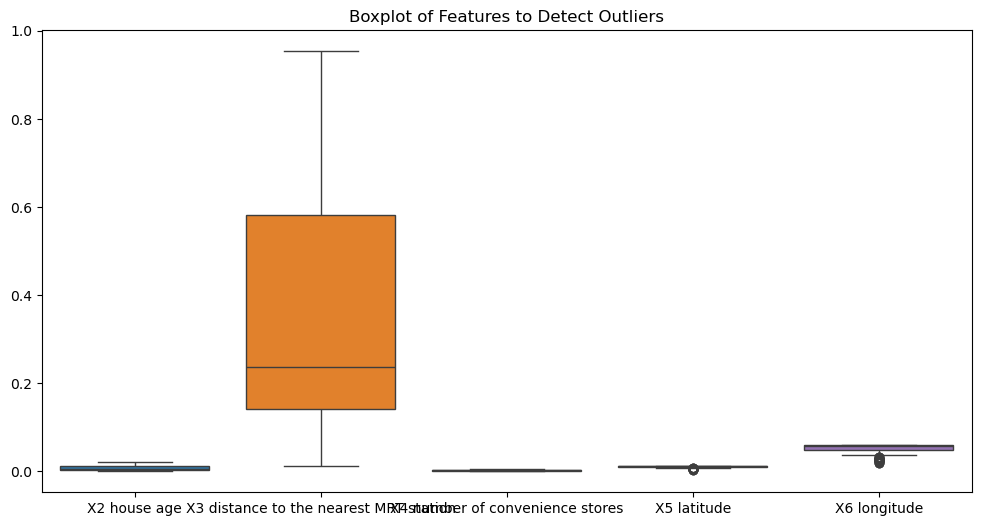

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define features
x = a_nor.iloc[:, 2:7]

# Create boxplots for all features
plt.figure(figsize=(12,6))
sns.boxplot(data=x)
plt.title("Boxplot of Features to Detect Outliers")
plt.show()


Boxplots were used to visually inspect outliers in the feature variables.
Most features show compact distributions with few outliers, mainly related to geographical variables (latitude and longitude).
These outliers were retained as they represent real-world variability.


## 🎯 Target Variable Analysis (House Price)

The target variable is `Y house price of unit area`.

Understanding its distribution is essential because:
- It affects model performance
- It helps identify skewness and extreme values
- It guides potential data transformations
- 

## 🧩 Feature Selection and Target Definition

At this stage, we separate the dataset into:
- **Independent variables (X)**: features used to predict house prices
- **Dependent variable (y)**: the target we want to predict
- 

In [ ]:
# Select relevant features (columns 2 to 6 for X) and target (column 7 for y)
X = a.iloc[:, 2:7]#Selects columns 2 to 6 (features) for training.(pick only the relevant independent variables.)
y = a.iloc[:, 7:8]#Selects the target variable (column at index 7) and stores it in y(This is what we want to predict, e.g., house prices.)

print("Selected features preview:")
display(X.head())
print("Target variable preview:")
display(y.head())

Selected features preview:


,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,32.0,84.87882,10,24.98298,121.54024
1,19.5,306.59470,9,24.98034,121.53951
2,13.3,561.98450,5,24.98746,121.54391
3,13.3,561.98450,5,24.98746,121.54391
4,5.0,390.56840,5,24.97937,121.54245


Target variable preview:


,Y house price of unit area
0,37.9
1,42.2
2,47.3
3,54.8
4,43.1


## 🧩 Feature Analysis

Each feature represents a different aspect of a property:

- `X2 house age`: Older houses may have lower prices
- `X3 distance to MRT`: Accessibility to public transport is expected to influence price
- `X4 number of convenience stores`: More nearby facilities may increase property value
- `Latitude and Longitude`: Capture location-based price differences
- 

## 📊 Feature Distribution Analysis

To better understand the characteristics of the dataset, we analyze the distribution of the main features using histograms.  
This helps identify data spread, skewness, and potenmtial outliers.

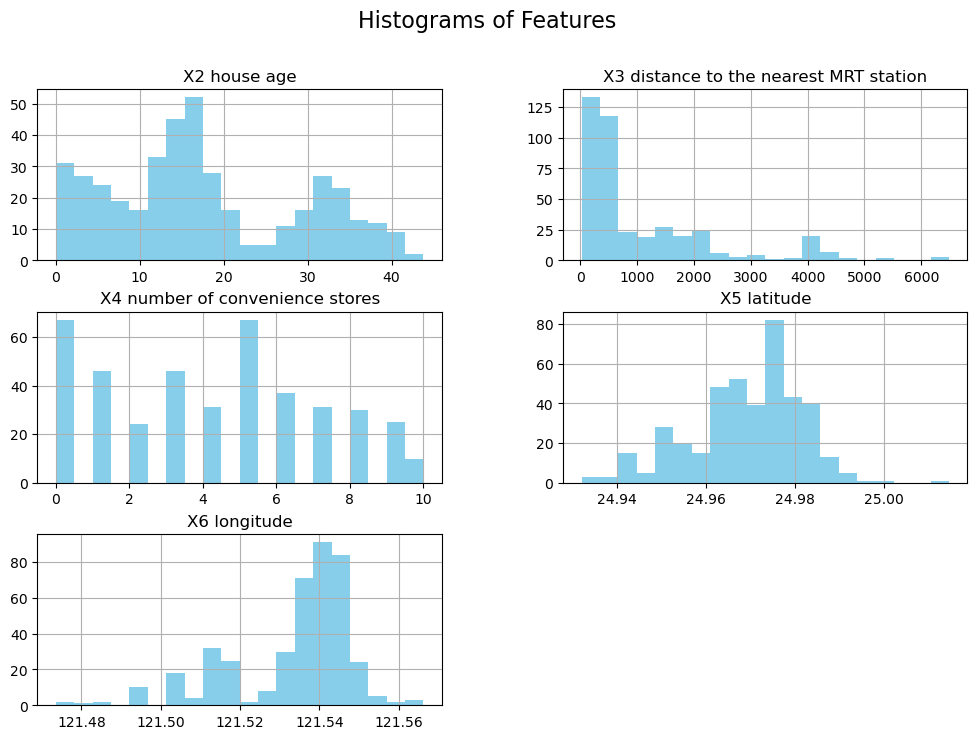

In [ ]:
X.hist(figsize=(12,8), bins=20, color='skyblue')
plt.suptitle("Histograms of Features", fontsize=16)
plt.show()

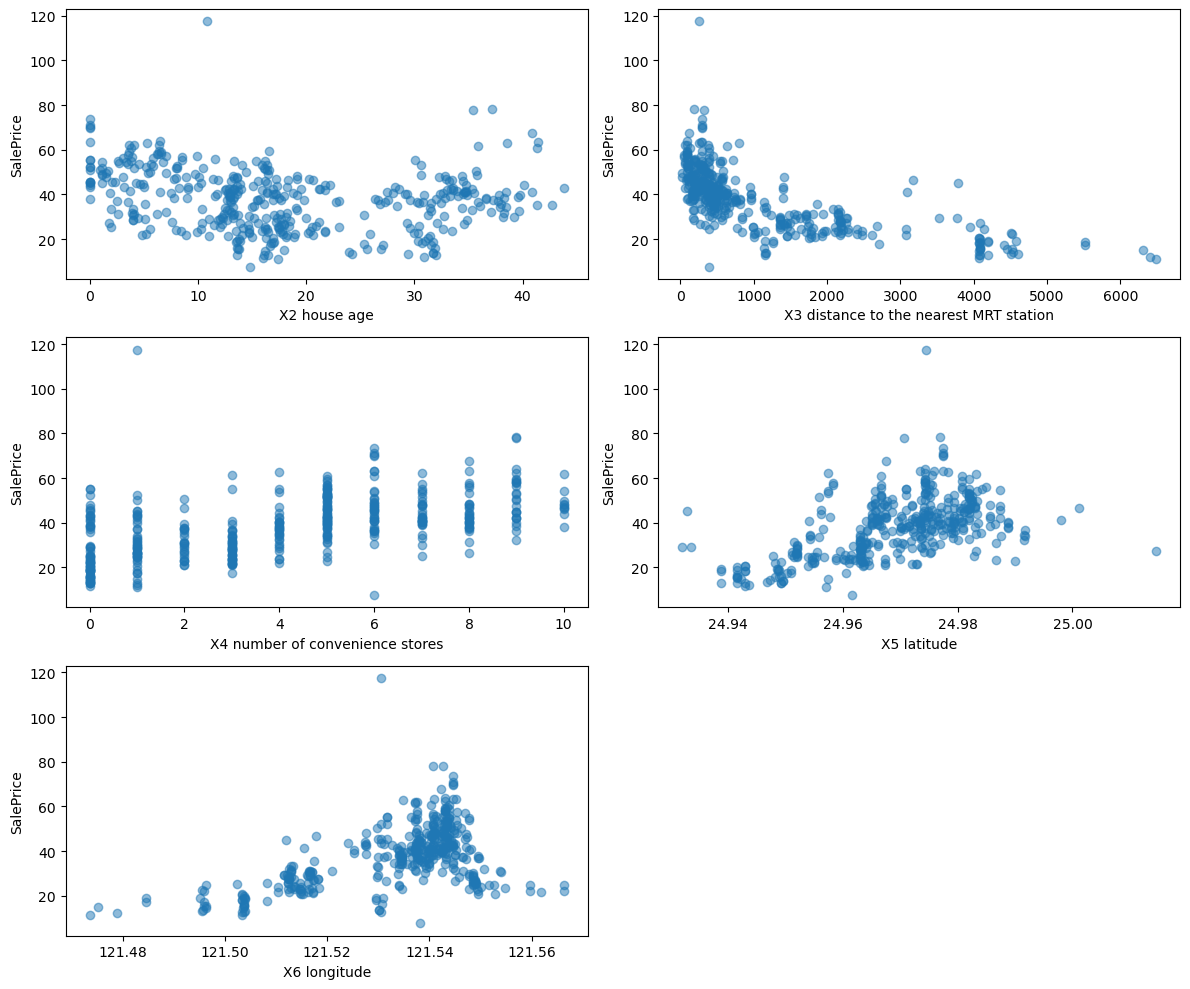

In [22]:
#4.3
plt.figure(figsize=(12,10))

for i, feature in enumerate(a1.columns):
    plt.subplot(3, 2, i+1)  # Adjust rows/columns depending on number of features
    plt.scatter(a1[feature], y, alpha=0.5)#lots a scatter plot of one feature (x-axis) vs the target y (y-axis).Shows how each feature is related to SalePrice, helps identify trends or correlations.
   #Adds axis labels.
    plt.xlabel(feature)#feature name
    plt.ylabel('SalePrice')#target name

plt.tight_layout #Adjusts spacing between subplots automatically so titles and labels don’t overlap.
plt.show() #Displays the figure in the notebook.

## Feature Relationships with House Price

### Key Observations

- House price **decreases** as distance to MRT increases
- Houses with more nearby convenience stores tend to be more expensive
- Location (latitude and longitude) strongly influences price
- House age has a weaker relationship with price

These plots show that accessibility and location are major price drivers.

## Correlation Analysis

-Check which features are most correlated with the target (e.g.,SalePrice).

-Can help feature selection before training your model

-Useful to see which features are strongly related to each other and to the target.

In [46]:
x.corr()#computes pairwise correlation between columns in x. 
#Find which features are strongly related to each other.
a_nor.corr()
#Check which features are most correlated with the target (e.g.,SalePrice).Can help feature selection before training your model
#Useful to see which features are strongly related to each other and to the target.

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
No,1.000000,0.292711,0.074387,-0.312275,0.181925,0.292721,0.292729,0.214413
X1 transaction date,0.292711,1.000000,0.299251,-0.945430,0.637209,0.999998,1.000000,0.791781
X2 house age,0.074387,0.299251,1.000000,-0.259074,0.231937,0.299377,0.299227,0.062916
X3 distance to the nearest MRT station,-0.312275,-0.945430,-0.259074,1.000000,-0.720186,-0.945451,-0.945456,-0.849005
X4 number of convenience stores,0.181925,0.637209,0.231937,-0.720186,1.000000,0.637411,0.637208,0.658818
X5 latitude,0.292721,0.999998,0.299377,-0.945451,0.637411,1.000000,0.999998,0.792012
X6 longitude,0.292729,1.000000,0.299227,-0.945456,0.637208,0.999998,1.000000,0.791731
Y house price of unit area,0.214413,0.791781,0.062916,-0.849005,0.658818,0.792012,0.791731,1.000000


### Data Preparation / Feature Selection

In Linear Regression, you need to separate:Features (X / independent variables)Target (y / dependent variable)

In [ ]:
x=a_nor.iloc[:,2:7]
x
#iloc → selects rows and columns by index (position-based).
#: → all rows
#2:7 → columns 2, 3, 4, 5, 6 (Python stops before 7)

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,0.015848,0.042037,0.004953,0.012373,0.060194
1,0.009557,0.150258,0.004411,0.012243,0.059565
2,0.006349,0.268276,0.002387,0.011928,0.058022
3,0.006349,0.268263,0.002387,0.011928,0.058019
4,0.002434,0.190095,0.002434,0.012158,0.059156
...,...,...,...,...,...
409,0.002997,0.892920,0.000000,0.005456,0.026578
410,0.002718,0.043899,0.004368,0.012120,0.058985
411,0.008969,0.186531,0.003340,0.011918,0.057987
412,0.003928,0.050829,0.002425,0.012108,0.058942


In [33]:
y=a_nor.iloc[:,7:8]
y


,Y house price of unit area
0,0.018770
1,0.020682
2,0.022580
3,0.026159
4,0.020977
...,...
409,0.003369
410,0.024265
411,0.019370
412,0.025460


## correlation heatmap

The correlation matrix highlights strong relationships between several variables and the target:

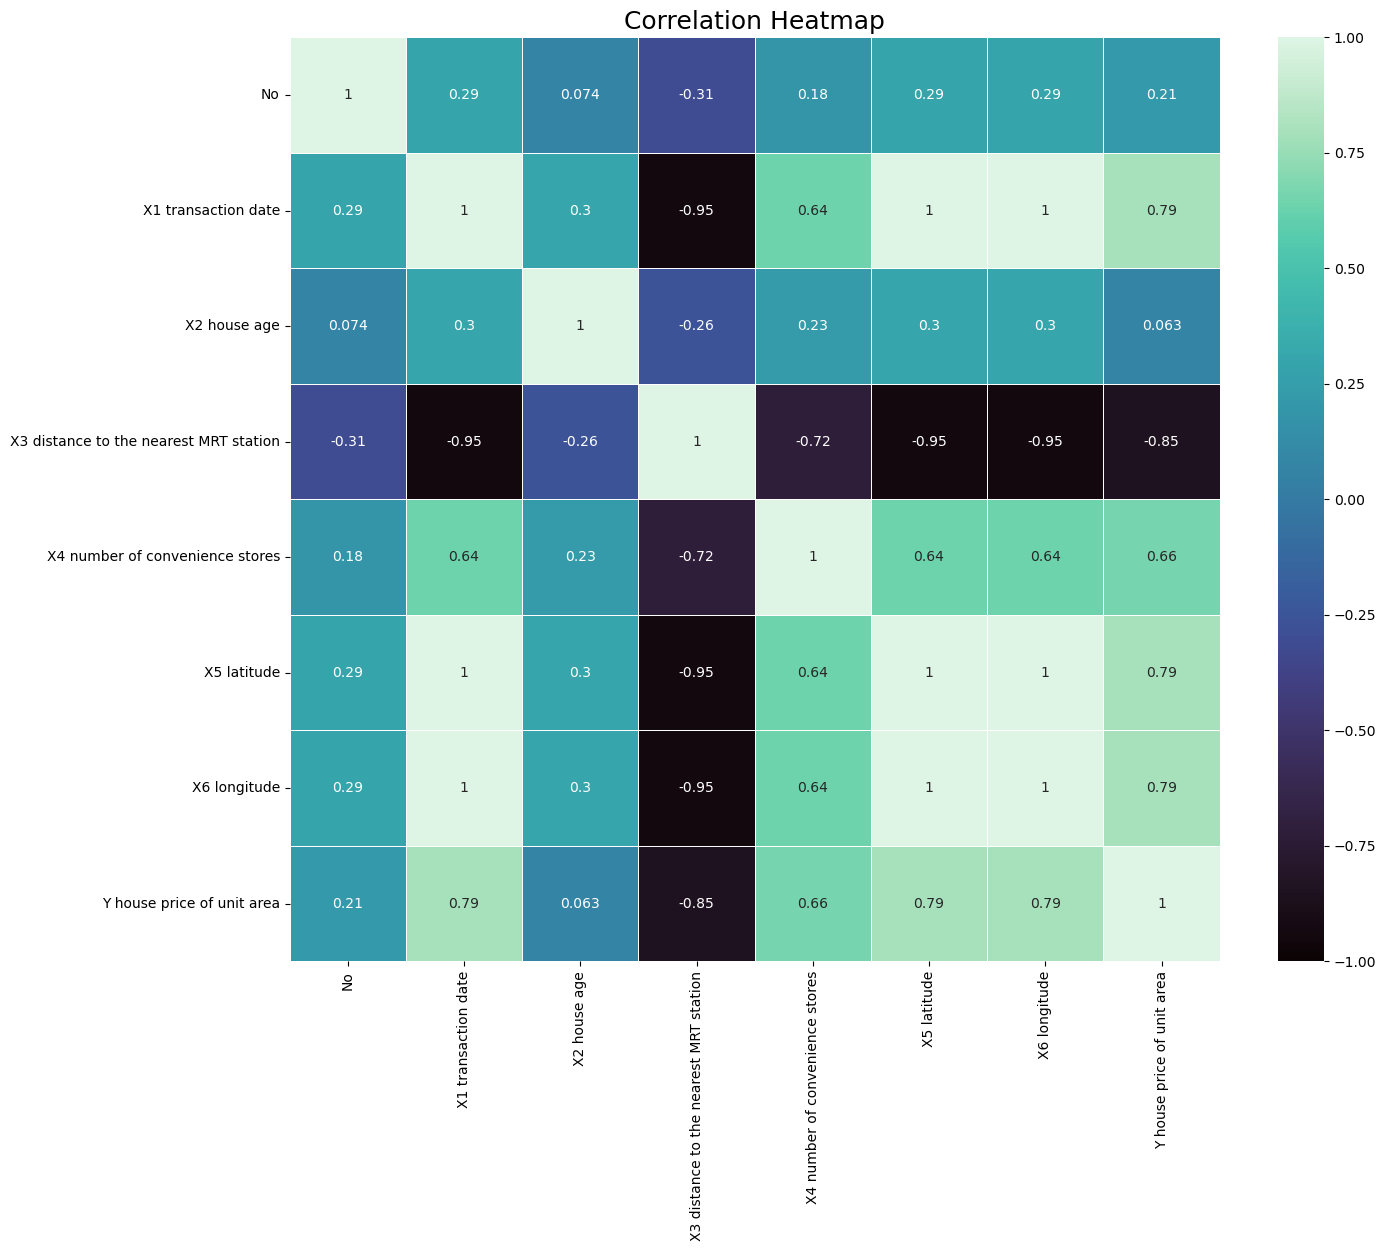

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Correlation heatmap (numeric columns only)

# Figure size
fig, ax = plt.subplots(figsize=(15, 12))

# Select only numeric columns (all columns in a_nor are numeric)
numeric_df = a_nor.select_dtypes(include=np.number)

# Compute correlation matrix
corr_matrix = numeric_df.corr(method='pearson')

# Plot heatmap with aquatic colormap
sns.heatmap(corr_matrix,
            ax=ax,
            cmap="mako",    #  colormap
            annot=True,       # show correlation values
            linewidths=0.5,   # lines between cells
            vmin=-1,          # min correlation
            vmax=1,           # max correlation
            center=0)         # center colormap at 0

# Title
plt.title('Correlation Heatmap', fontsize=18)
plt.show()

### Key Observations

- **Distance to MRT (X3)** has a **strong negative correlation (-0.85)** with house price.
  - Houses farther from MRT stations tend to be cheaper.
- **Number of convenience stores (X4)** shows a **strong positive correlation (~0.66)** with price.
- **Latitude and longitude** are highly correlated with house price (~0.79), indicating the importance of location.
- **House age (X2)** shows a weak negative correlation with price
- 

### Interpretation

Houses closer to MRT stations and in well-developed areas
are significantly more expensive.

## Normalization

Features have different scales (distance, latitude, price).
Normalization was applied to ensure:

- Fair contribution of all features
- Better performance for regression models
- Improved numerical stability

The normalized dataset will be used in the next notebook.

### !!!normalizing the data:

In [25]:
import pandas as pd
from sklearn import preprocessing #Imports the preprocessing module from scikit-learn, which contains functions for scaling and normalizing data.
a_nor=preprocessing.normalize(a)#Ensures that all features contribute proportionally and no single feature dominates because of its scale.
a_nor=pd.DataFrame(a_nor)#Converts the numpy array returned by normalize() back into a pandas DataFrame.
a_nor
a_nor.columns=a.columns #Assigns the original column names to the normalized DataFrame.So you don’t lose the column names during normalization
print("Normalized dataset preview:")
a_nor

Normalized dataset preview:


,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,0.000495,0.996909,0.015848,0.042037,0.004953,0.012373,0.060194,0.018770
1,0.000980,0.986502,0.009557,0.150258,0.004411,0.012243,0.059565,0.020682
2,0.001432,0.961229,0.006349,0.268276,0.002387,0.011928,0.058022,0.022580
3,0.001909,0.961141,0.006349,0.268263,0.002387,0.011928,0.058019,0.026159
4,0.002434,0.979673,0.002434,0.190095,0.002434,0.012158,0.059156,0.020977
...,...,...,...,...,...,...,...,...
409,0.089685,0.440334,0.002997,0.892920,0.000000,0.005456,0.026578,0.003369
410,0.199460,0.976753,0.002718,0.043899,0.004368,0.012120,0.058985,0.024265
411,0.196565,0.960519,0.008969,0.186531,0.003340,0.011918,0.057987,0.019370
412,0.200288,0.976223,0.003928,0.050829,0.002425,0.012108,0.058942,0.025460


In [ ]:
# Export normalized/cleaned dataset to CSV
import pandas as pd

a_nor = pd.read_csv(
    r"C:\Users\bka20\OneDrive\Desktop\Project ML\Data\realestate_cleaned.csv"
)
